# KFC Trustpilot Reviews - Sentiment Analysis
**Author:** Mehdi Gurbanzade · M.Sc. Data Science  


## Table of Contents
1. Introduction
2. Data Collection
3. Exploratory Data Analysis
4. Sentiment Analysis
5. Mismatch Detection
6. Machine Learning
7. Results & Comparison
8. Conclusion


## 1. Introduction

the main question here is whether the written part of a review actually matches the star rating. on trustpilot you give a number from 1 to 5 and also write a comment. normally these should tell the same story but sometimes they don't — someone writes something positive but still gives 1 star, or complains but gives 5. i wanted to find those cases for kfc.

to do this i scraped kfc reviews from trustpilot (402 unique reviews after cleaning), ran sentiment analysis on the text, looked for the mismatches, and also tried to predict the star rating from the review text using three ml models.

In [1]:

import warnings
warnings.filterwarnings('ignore')

# basic data stuff
import pandas as pd
import numpy as np

# for sentiment
from textblob import TextBlob

# ml stuff
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# plots
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams.update({'figure.dpi': 120, 'figure.figsize': (8, 4)})




## 2. Data Collection

Trustpilot loads its content with javascript so a normal scraper wouldn't work. i used selenium which actually opens a browser and waits for everything to load.

i scraped 20 pages from the kfc trustpilot page and pulled the review text, the star rating, and the date for each review. ended up with 480 rows from march to june 2025. The scraping code is in the scraper_KFC.py file, the csv is already there.

two problems showed up in the raw data, so i clean them right after loading:
- **truncated text** — trustpilot cuts long reviews in the list view and adds a "See more" link. the scraper picked up that text, so 40 reviews end with "See more" and are missing their ending. i strip the "See more" part; the rest of the text is still usable but those 40 reviews are incomplete.
- **duplicates** — trustpilot shows the same 4 featured reviews on every page, so the scraper collected each of them ~20 times. that's 78 duplicate rows. i drop exact duplicates (same text, rating and date), which leaves **402 unique reviews**.

In [2]:
# load the csv
df = pd.read_csv("trustpilot_kfc_reviews.csv", parse_dates=["date"])

# trustpilot cuts long reviews in the list view and adds a "See more" link --
# the scraper picked that up, so strip it from the end of the text
truncated = df['review'].str.contains(r'See more\s*$', regex=True)
df['review'] = df['review'].str.replace(r'\s*See more\s*$', '', regex=True).str.strip()
print(f"Truncated reviews ('See more' removed): {truncated.sum()} of {len(df)}")

# trustpilot shows the same few featured reviews on every page, so the scraper
# collected them ~20 times each -- drop exact duplicates (same text, rating and date)
n_before = len(df)
df = df.drop_duplicates(subset=['review', 'rating', 'date']).reset_index(drop=True)
print(f"Duplicate rows removed: {n_before - len(df)} -> {len(df)} unique reviews")

print(f"Dataset shape : {df.shape}")
print(f"Date range    : {df['date'].min().date()} -> {df['date'].max().date()}")
print(f"Null values   :\n{df.isnull().sum()}")
print()
df.head()


Truncated reviews ('See more' removed): 40 of 480
Duplicate rows removed: 78 -> 402 unique reviews
Dataset shape : (402, 3)
Date range    : 2025-03-08 -> 2025-06-16
Null values   :
review    0
rating    0
date      0
dtype: int64



,review,rating,date
0,I have not tried a KFC at all before this meal...,3,2025-06-15 18:36:22+00:00
1,"The kfc in Lincoln Park was great tonight, rea...",5,2025-05-22 02:04:54+00:00
2,I had a bad experience one time and I wrote co...,5,2025-04-22 22:29:02+00:00
3,The manager Miss Walton was very professional ...,5,2025-05-28 21:14:25+00:00
4,me and my wife went to the kfc in johnstown pa...,1,2025-06-16 05:00:57+00:00


after cleaning — 402 unique reviews, 3 columns, no missing values. dates go from march 8 to june 16 2025.

## 3. Exploratory Data Analysis

before doing anything else i just want to get a feel for the data — how are the ratings spread, how many reviews per month, and do unhappy customers tend to write longer reviews.

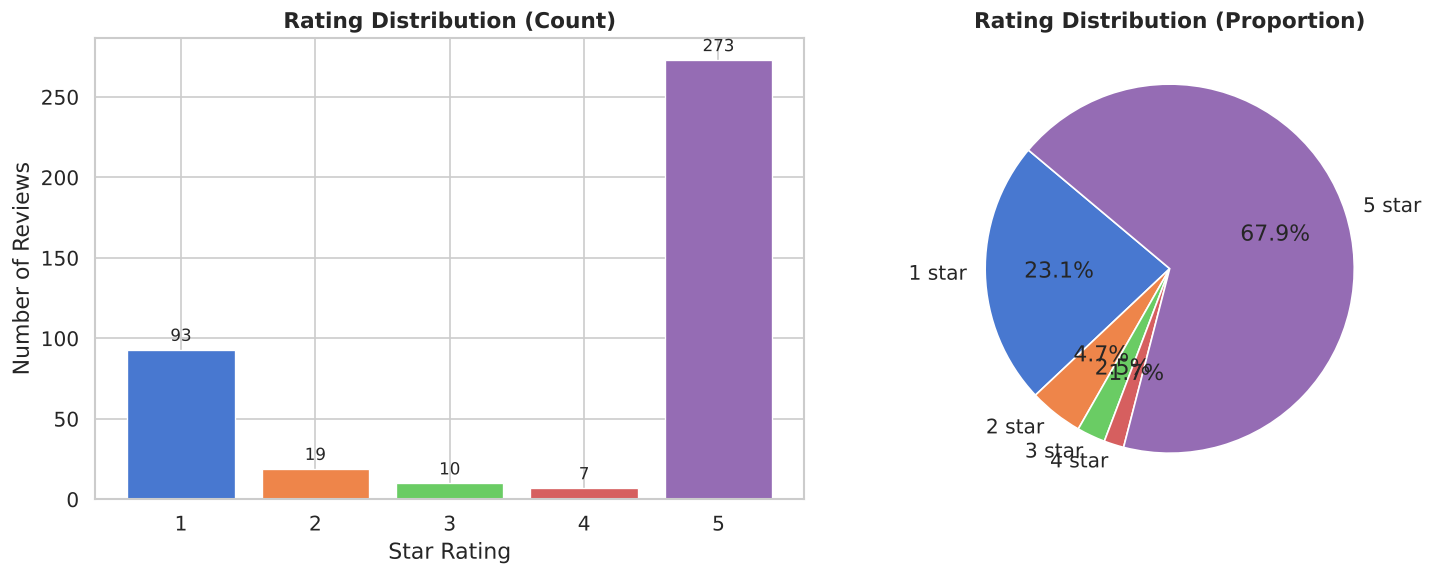

Rating distribution summary:
        Count  Percentage
rating                   
1          93        23.1
2          19         4.7
3          10         2.5
4           7         1.7
5         273        67.9


In [3]:
# rating distribution -- bar chart + pie chart side by side
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

rating_counts = df['rating'].value_counts().sort_index()
axes[0].bar(
    rating_counts.index, rating_counts.values,
    color=sns.color_palette('muted', 5), edgecolor='white', linewidth=0.8
)
axes[0].set_title('Rating Distribution (Count)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Number of Reviews')
for bar, val in zip(axes[0].patches, rating_counts.values):
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 3, str(val),
        ha='center', va='bottom', fontsize=10
    )

# pie chart
axes[1].pie(
    rating_counts.values,
    labels=[f'{i} star' for i in rating_counts.index],
    autopct='%1.1f%%',
    colors=sns.color_palette('muted', 5),
    startangle=140,
    wedgeprops={'edgecolor': 'white'}
)
axes[1].set_title('Rating Distribution (Proportion)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# print the numbers too
print("Rating distribution summary:")
print(df['rating'].value_counts().sort_index().rename('Count').to_frame()
      .assign(Percentage=lambda x: (x['Count'] / len(df) * 100).round(1))
      .to_string())


so the ratings are really uneven. **273 reviews (67.9%) are 5-star** and **93 (23.1%) are 1-star**. the three middle ratings only make up about 9% combined (only 10 three-star reviews left after removing duplicates). basically people either loved it or hated it — not much in between. this is going to be a problem later for the ml models.

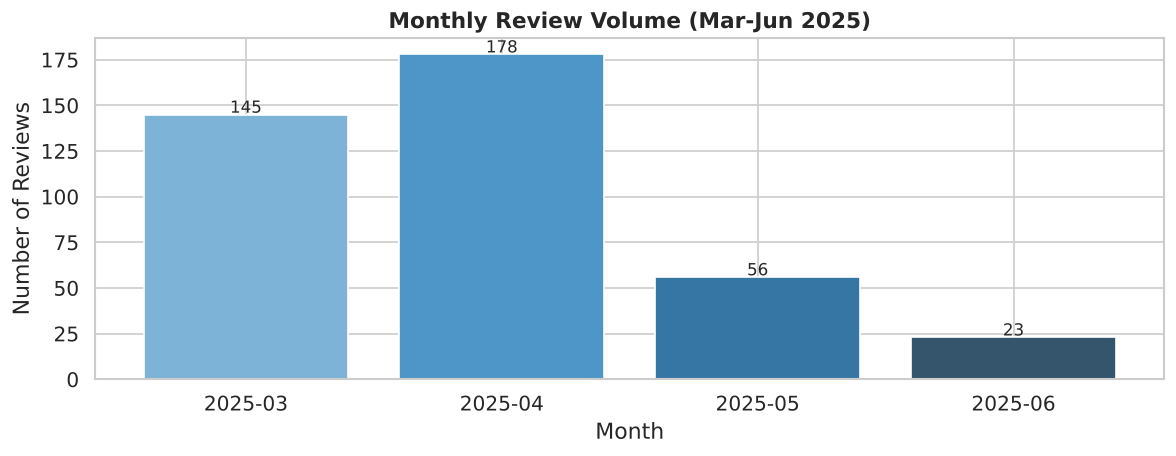

In [4]:
# how many reviews per month
monthly = df.groupby(df['date'].dt.to_period('M')).size().reset_index()
monthly.columns = ['month', 'count']
monthly['month_str'] = monthly['month'].astype(str)

plt.figure(figsize=(10, 4))
plt.bar(monthly['month_str'], monthly['count'],
        color=sns.color_palette('Blues_d', len(monthly)),
        edgecolor='white')
plt.title('Monthly Review Volume (Mar-Jun 2025)', fontsize=13, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
for i, row in monthly.iterrows():
    plt.text(i, row['count'] + 1, str(row['count']), ha='center', fontsize=10)
plt.tight_layout()
plt.show()


april had the most reviews (178), march had 145. may (56) and june (23) are lower probably because june was still ongoing when i scraped. nothing weird here.

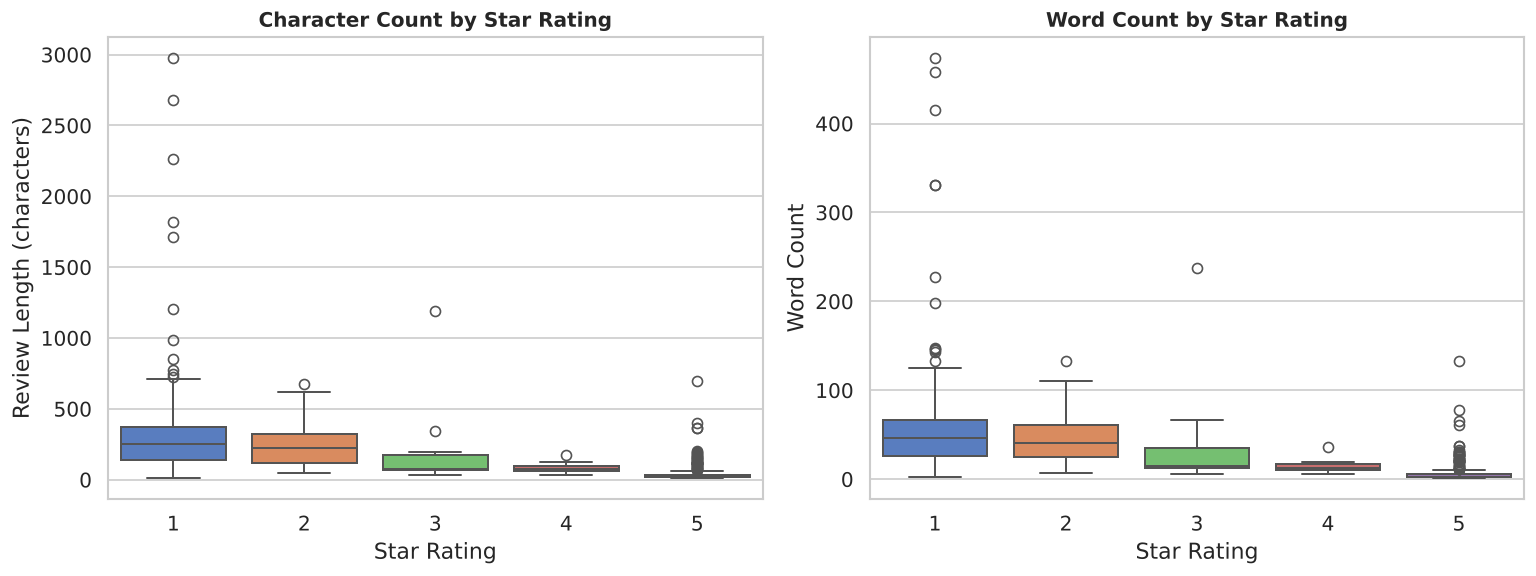

character count by rating:
        count   mean    std   min    25%    50%    75%     max
rating                                                        
1        93.0  389.4  519.0  12.0  142.0  252.0  373.0  2978.0
2        19.0  266.0  188.6  44.0  117.0  225.0  319.5   678.0
3        10.0  221.1  353.2  34.0   65.2   73.0  176.2  1190.0
4         7.0   86.4   48.3  34.0   62.0   73.0   98.5   177.0
5       273.0   45.3   64.1  10.0   18.0   34.0   36.0   694.0


In [5]:
# calculate review length and word count
df['review_length'] = df['review'].apply(lambda x: len(str(x)))
df['word_count']    = df['review'].apply(lambda x: len(str(x).split()))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='rating', y='review_length',
            palette='muted', ax=axes[0], linewidth=1.2)
axes[0].set_title('Character Count by Star Rating', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Review Length (characters)')

sns.boxplot(data=df, x='rating', y='word_count',
            palette='muted', ax=axes[1], linewidth=1.2)
axes[1].set_title('Word Count by Star Rating', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Star Rating')
axes[1].set_ylabel('Word Count')

plt.tight_layout()
plt.show()

# quick stats
print("character count by rating:")
print(df.groupby('rating')['review_length'].describe().round(1).to_string())


1-star reviews are noticeably longer — around **389 characters** on average vs only **45** for 5-star ones. makes sense, when something goes wrong people want to explain what happened.

### quick summary

main thing here is the huge imbalance — almost 68% of reviews are 5-star. this is going to cause issues when training the models since there's barely any data for 2, 3, and 4-star reviews. also confirmed that unhappy customers write longer reviews, which is pretty much what you'd expect.

## 4. Sentiment Analysis

the raw data only has the review text, rating, and date. i created some extra features from the text:

- **sentiment** — a score from -1 (very negative) to +1 (very positive), from textblob
- **subjectivity** — how opinionated the text is, 0 means factual, 1 means very personal
- **sentiment_label** — just positive / neutral / negative based on the score
- **review_length** — character count
- **word_count** — number of words
- **rating_group** — low (1-2 stars), neutral (3 stars), high (4-5 stars)

textblob works by looking up each word in a dictionary and averaging the scores. it's fast and simple but doesn't understand context or sarcasm which is a problem for the mismatch part.

i used ±0.10 as the cutoff instead of the more common ±0.20 because with 0.20 too many short reviews end up as neutral even when they're clearly a bit positive or negative.

In [6]:
# get sentiment score and subjectivity from textblob
# polarity is -1 to +1, subjectivity is 0 to 1

def get_sentiment(text):
    return TextBlob(str(text)).sentiment.polarity

def get_subjectivity(text):
    return TextBlob(str(text)).sentiment.subjectivity

# label as positive / neutral / negative
# using 0.10 threshold -- less stuff ends up as neutral compared to 0.20
def label_sentiment(score):
    if score > 0.10:
        return 'Positive'
    elif score < -0.10:
        return 'Negative'
    else:
        return 'Neutral'

df['sentiment']       = df['review'].apply(get_sentiment)
df['subjectivity']    = df['review'].apply(get_subjectivity)
df['sentiment_label'] = df['sentiment'].apply(label_sentiment)

print("Sentiment label distribution:")
print(df['sentiment_label'].value_counts().to_string())
print()
print("Sentiment score statistics:")
print(df['sentiment'].describe().round(4).to_string())


Sentiment label distribution:
sentiment_label
Positive    207
Neutral     134
Negative     61

Sentiment score statistics:
count    402.0000
mean       0.2723
std        0.4447
min       -1.0000
25%        0.0000
50%        0.1926
75%        0.7000
max        1.0000


207 reviews (51.5%) came out as positive, 134 (33.3%) neutral, and 61 (15.2%) negative. average polarity is +0.27 so it leans slightly positive. interesting that this doesn't fully match the rating distribution — a lot of 5-star reviews are short ("good", "great food") and textblob scores many of them as neutral, which already hints at some mismatch.

In [7]:
# group ratings into low / neutral / high
def group_rating(r):
    if r in [1, 2]:
        return 'Low'
    elif r == 3:
        return 'Neutral'
    else:
        return 'High'

df['rating_group'] = df['rating'].apply(group_rating)

print("Rating group distribution:")
print(df['rating_group'].value_counts().to_string())


Rating group distribution:
rating_group
High       280
Low        112
Neutral     10


280 reviews (69.7%) are in the high group (4-5 stars), 112 (27.9%) low (1-2 stars), and only 10 (2.5%) neutral. same polarised pattern as the ratings.

In [8]:
# quick look at the dataset with all new columns
cols_display = ['review', 'rating', 'sentiment', 'subjectivity',
                'sentiment_label', 'review_length', 'word_count', 'rating_group']
df[cols_display].head(8)


,review,rating,sentiment,subjectivity,sentiment_label,review_length,word_count,rating_group
0,I have not tried a KFC at all before this meal...,3,0.000000,0.000000,Neutral,199,40,Neutral
1,"The kfc in Lincoln Park was great tonight, rea...",5,0.347917,0.583333,Positive,197,37,High
2,I had a bad experience one time and I wrote co...,5,0.016000,0.333333,Neutral,161,31,High
3,The manager Miss Walton was very professional ...,5,0.443333,0.676667,Positive,115,19,High
4,me and my wife went to the kfc in johnstown pa...,1,-0.284722,0.637500,Negative,463,94,Low
5,"Horrible taste, uncooked chicken!!",1,-0.679167,0.683333,Negative,34,4,Low
6,I have not tried a KFC at all before this meal...,3,-0.125000,0.300000,Negative,347,67,Neutral
7,The KFC in Alloa. This was the first time I ha...,1,-0.314583,0.618750,Negative,278,59,Low


dataset now has 8 columns instead of 3. all the new features are ready.

## 5. Mismatch Detection

this is the main part. i want to see if the written text actually matches the star rating. i'll use a few charts to look at it from different angles and then find the reviews where they don't agree.

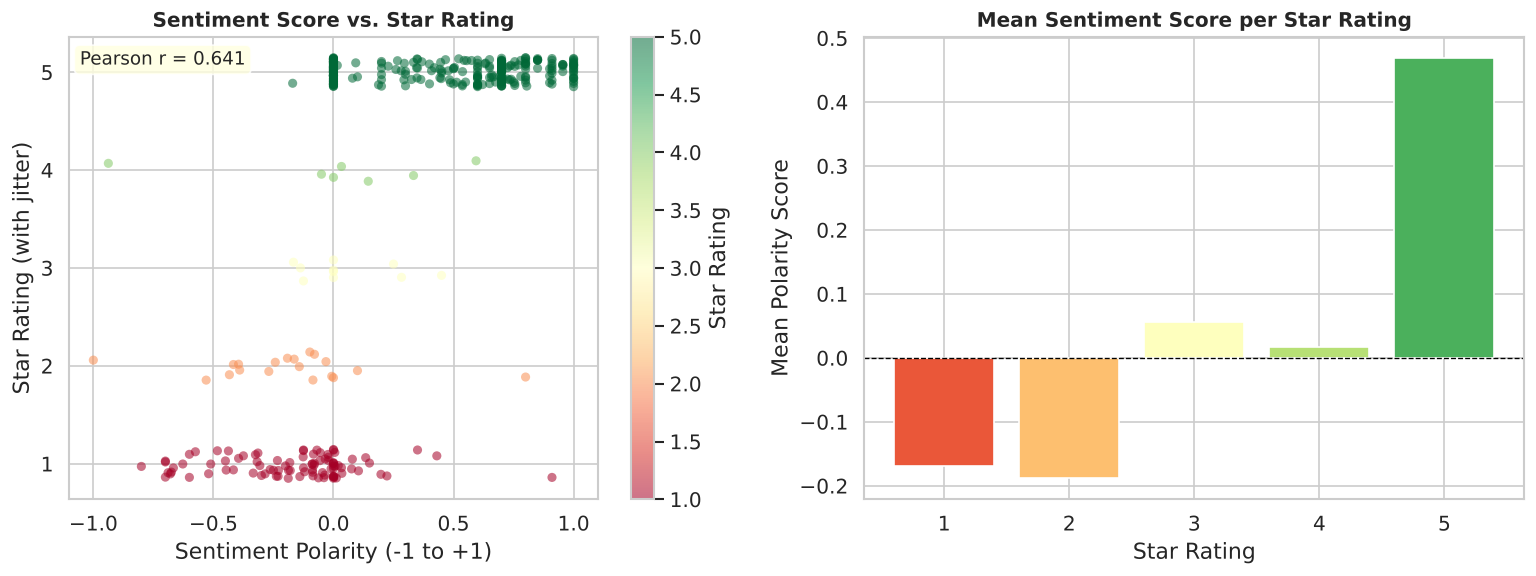

Pearson correlation (sentiment vs rating): 0.6407


In [9]:
# scatter plot -- sentiment score vs star rating
# added jitter so overlapping dots are easier to see
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

np.random.seed(42)
jitter = np.random.uniform(-0.15, 0.15, len(df))
scatter = axes[0].scatter(
    df['sentiment'],
    df['rating'] + jitter,
    c=df['rating'], cmap='RdYlGn',
    alpha=0.55, edgecolors='none', s=30
)
axes[0].set_title('Sentiment Score vs. Star Rating', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sentiment Polarity (-1 to +1)')
axes[0].set_ylabel('Star Rating (with jitter)')
axes[0].yaxis.set_major_locator(mticker.MultipleLocator(1))
plt.colorbar(scatter, ax=axes[0], label='Star Rating')

# show pearson r on the plot
corr = df['sentiment'].corr(df['rating'])
axes[0].text(
    0.02, 0.97, f'Pearson r = {corr:.3f}',
    transform=axes[0].transAxes, va='top', fontsize=11,
    bbox=dict(boxstyle='round,pad=0.3', facecolor='lightyellow', alpha=0.8)
)

# mean sentiment per rating on the right
corr_vals = df.groupby('rating')['sentiment'].mean()
axes[1].bar(corr_vals.index, corr_vals.values,
            color=sns.color_palette('RdYlGn', 5), edgecolor='white')
axes[1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[1].set_title('Mean Sentiment Score per Star Rating', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Star Rating')
axes[1].set_ylabel('Mean Polarity Score')

plt.tight_layout()
plt.show()

print(f"Pearson correlation (sentiment vs rating): {corr:.4f}")


the pearson correlation between sentiment score and star rating is **r = 0.64** — a moderate-to-strong positive link. generally higher sentiment = higher rating but there's a lot of scatter. some 5-star reviews have near-zero or even negative polarity, and some 1-star reviews score positive. so they don't always agree.

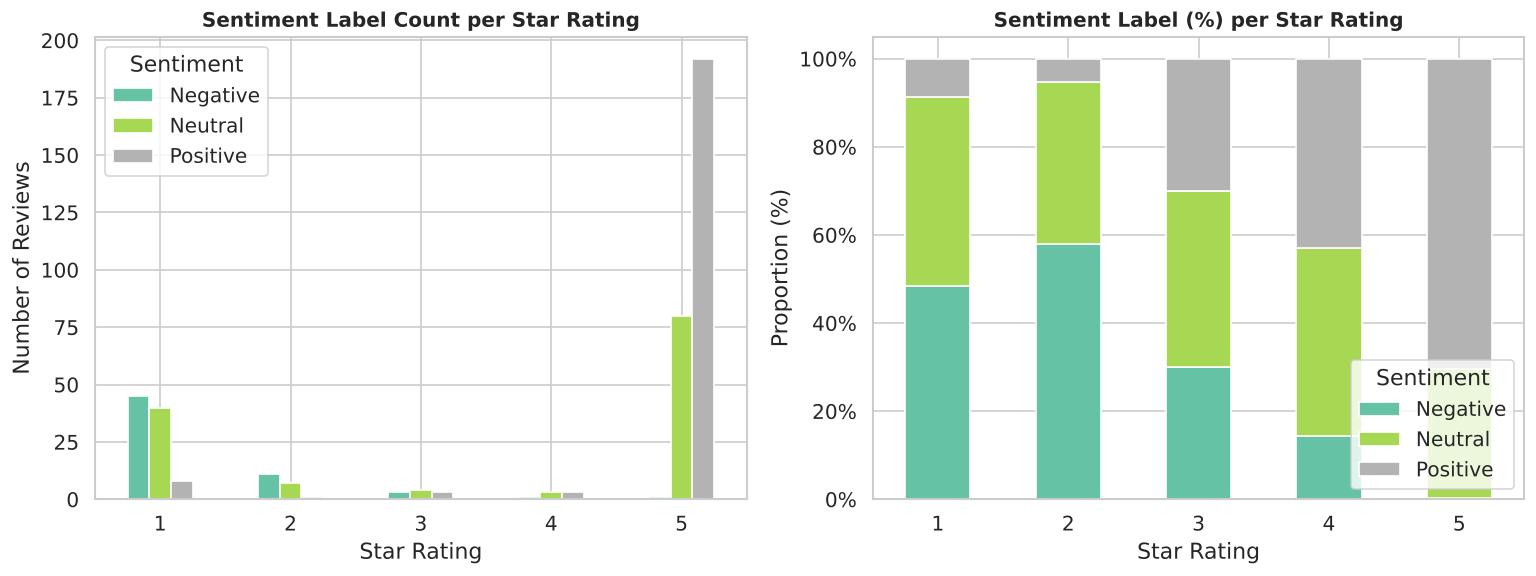

cross-tabulation (counts):
sentiment_label  Negative  Neutral  Positive
rating                                      
1                      45       40         8
2                      11        7         1
3                       3        4         3
4                       1        3         3
5                       1       80       192


In [10]:
# how are sentiment labels spread across each star rating?
cross = pd.crosstab(df['rating'], df['sentiment_label'])
cross_pct = cross.div(cross.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# raw counts
cross.plot(kind='bar', ax=axes[0], colormap='Set2', edgecolor='white', rot=0)
axes[0].set_title('Sentiment Label Count per Star Rating', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Star Rating')
axes[0].set_ylabel('Number of Reviews')
axes[0].legend(title='Sentiment')

# same but as percentages
cross_pct.plot(kind='bar', ax=axes[1], colormap='Set2', edgecolor='white',
               rot=0, stacked=True)
axes[1].set_title('Sentiment Label (%) per Star Rating', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Star Rating')
axes[1].set_ylabel('Proportion (%)')
axes[1].legend(title='Sentiment', loc='lower right')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())

plt.tight_layout()
plt.show()

print("cross-tabulation (counts):")
print(cross.to_string())


most 5-star reviews are labeled positive (192 out of 273) which makes sense. but **80 five-star reviews came out as neutral** — probably short or vague text. more importantly, **8 one-star reviews were labeled positive by textblob** — those are the mismatches.

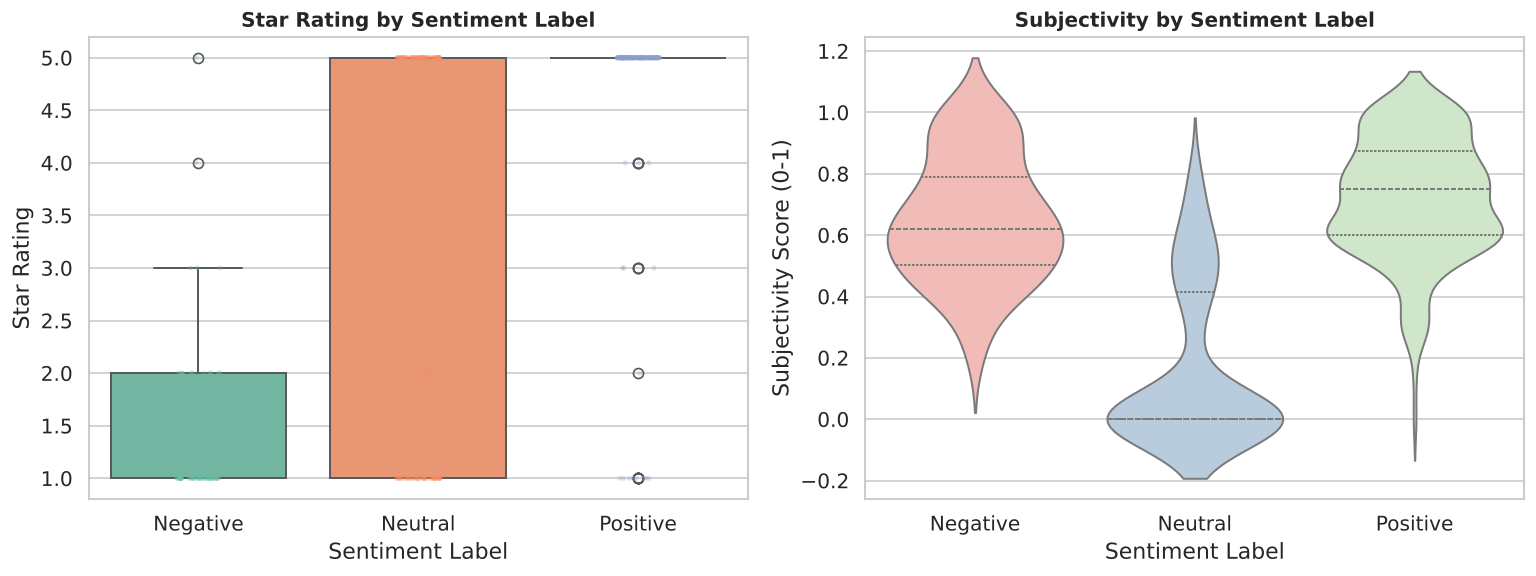

In [11]:
# boxplot: does rating differ by sentiment label?
# also violin plot for subjectivity
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

label_order = ['Negative', 'Neutral', 'Positive']

sns.boxplot(data=df, x='sentiment_label', y='rating',
            order=label_order, palette='Set2', ax=axes[0], linewidth=1.2)
sns.stripplot(data=df, x='sentiment_label', y='rating',
              order=label_order, palette='Set2', ax=axes[0], alpha=0.3, jitter=True, size=3)
axes[0].set_title('Star Rating by Sentiment Label', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sentiment Label')
axes[0].set_ylabel('Star Rating')

sns.violinplot(data=df, x='sentiment_label', y='subjectivity',
               order=label_order, palette='Pastel1', ax=axes[1], inner='quartile', linewidth=1.2)
axes[1].set_title('Subjectivity by Sentiment Label', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Sentiment Label')
axes[1].set_ylabel('Subjectivity Score (0-1)')

plt.tight_layout()
plt.show()


negative-labeled reviews are almost always 1-star. positive ones are mostly 4-5 stars but a few have low ratings — those are the inconsistent ones. neutral reviews are all over the place which shows a neutral tone doesn't really tell you what rating someone gave.

In [12]:
# find the mismatches
# type a = positive text but low rating (1 or 2 stars)
# type b = negative text but high rating (4 or 5 stars)
mismatch_pos = df[(df['sentiment_label'] == 'Positive') & (df['rating'] <= 2)].copy()
mismatch_neg = df[(df['sentiment_label'] == 'Negative') & (df['rating'] >= 4)].copy()

total_mismatches = len(mismatch_pos) + len(mismatch_neg)
mismatch_rate    = total_mismatches / len(df) * 100

print(f"Type A (positive text + low rating) : {len(mismatch_pos)}")
print(f"Type B (negative text + high rating): {len(mismatch_neg)}")
print(f"Total mismatches: {total_mismatches} ({mismatch_rate:.1f}%)")
print()
print("Type A examples:")
print("-" * 60)
for _, row in mismatch_pos[['review', 'rating', 'sentiment']].head(5).iterrows():
    print(f"  Rating: {row['rating']} stars | Polarity: {row['sentiment']:+.3f}")
    print(f"  {str(row['review'])[:130]}...")
    print()

print("Type B examples:")
print("-" * 60)
for _, row in mismatch_neg[['review', 'rating', 'sentiment']].head(5).iterrows():
    print(f"  Rating: {row['rating']} stars | Polarity: {row['sentiment']:+.3f}")
    print(f"  {str(row['review'])[:130]}...")
    print()


Type A (positive text + low rating) : 9
Type B (negative text + high rating): 2
Total mismatches: 11 (2.7%)

Type A examples:
------------------------------------------------------------
  Rating: 1 stars | Polarity: +0.134
  They just reduced the size of the boneless mini filets the are easily under half of the size they where a few week back again srin...

  Rating: 1 stars | Polarity: +0.150
  Please don't go there unless you want to be spoken to any kind of way. The employees are so rude and so disrespectful. They should...

  Rating: 1 stars | Polarity: +0.104
  I ordered in WhatsApp and was told to pick up at 7pm. It’s has been an hour and there is no one giving us any updates and they jus...

  Rating: 1 stars | Polarity: +0.350
  I loved the Big Mac...

  Rating: 1 stars | Polarity: +0.198
  The chicken was flavorless, some pieces overcooked and it just wasn't worth the 8 piece for $10 price. Lees Famous Recipe is leaps...

Type B examples:
-------------------------------------

found **11 mismatches in total — 2.7% of the dataset**. **9 are type a** (positive text, low rating) and **2 are type b** (negative text, high rating). type a is more common — probably because some people write politely even when they're unhappy, or textblob just can't pick up on sarcasm. the type b examples actually show textblob's limits: "very very yummy chicken" and "just made my day!!" are clearly positive but got a negative score.

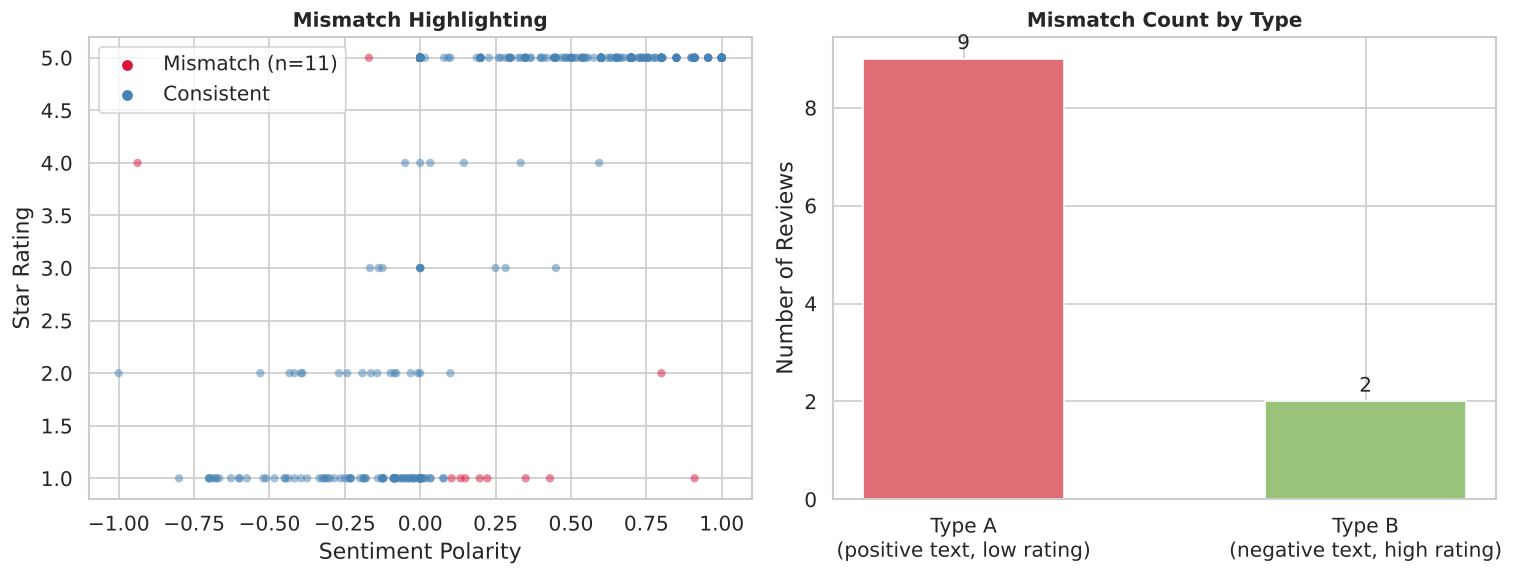

In [13]:
# mark mismatches and plot them
df['mismatch'] = (
    ((df['sentiment_label'] == 'Positive') & (df['rating'] <= 2)) |
    ((df['sentiment_label'] == 'Negative') & (df['rating'] >= 4))
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# scatter -- red dots are mismatches
colors = df['mismatch'].map({False: 'steelblue', True: 'crimson'})
axes[0].scatter(df['sentiment'], df['rating'],
                c=colors, alpha=0.5, s=25, edgecolors='none')
axes[0].scatter([], [], c='crimson', label=f'Mismatch (n={total_mismatches})', s=30)
axes[0].scatter([], [], c='steelblue', label='Consistent', s=30)
axes[0].set_title('Mismatch Highlighting', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Sentiment Polarity')
axes[0].set_ylabel('Star Rating')
axes[0].legend()

# bar chart showing how many of each type
bars = ['Type A\n(positive text, low rating)', 'Type B\n(negative text, high rating)']
vals = [len(mismatch_pos), len(mismatch_neg)]
axes[1].bar(bars, vals, color=['#e06c75', '#98c379'], edgecolor='white', width=0.5)
axes[1].set_title('Mismatch Count by Type', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Number of Reviews')
for bar, val in zip(axes[1].patches, vals):
    axes[1].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.2, str(val), ha='center', fontsize=12)

plt.tight_layout()
plt.show()


the red dots (mismatches) mostly show up in the top-left of the scatter — positive sentiment but low rating. only 2 are in the bottom-right. most reviews are consistent, the mismatches are clearly outliers.

### mismatch summary

only 2.7% of reviews had a mismatch which is not that many. most were type a — positive text with a low star rating. a few reasons this might happen:

- the person was being sarcastic and textblob didn't catch it
- they said something nice at the start before complaining
- textblob just isn't great at reading tone in short or ambiguous text

type b mismatches (negative text, high rating) were rare — probably cases where someone complained about one thing but was still happy overall.

## 6. Machine Learning

i want to see if i can predict the star rating from the review text. i'll try three models and compare them.

for features i used tfidf on the review text (top 2000 words and bigrams) plus the four numeric features — sentiment score, subjectivity, review length, and word count. that's 1453 features in total. the train/test split is done first and the tfidf vocabulary is learned only from the training reviews, so no information from the test set leaks into the features.

the three models:
- **logistic regression** — good starting point for text data
- **random forest** — uses lots of decision trees, can pick up patterns lr might miss
- **naive bayes** — simple and fast, tfidf only (can't use negative values)

one important thing — 67.9% of the data is 5-star so accuracy alone is misleading. a model that just always predicts 5-star would already get ~68%. that's why i also report macro f1 which treats all five classes equally.

In [14]:
# set up features and labels
y = df['rating']  # what we want to predict

# split first (80/20, stratified) so the tfidf vocabulary is learned only from the training reviews
train_idx, test_idx = train_test_split(
    df.index, test_size=0.2, random_state=42, stratify=y
)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

# tfidf on the review text -- top 2000 words and bigrams (fit on train only, no leakage)
tfidf = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), min_df=2)
X_text_train = tfidf.fit_transform(df.loc[train_idx, 'review']).toarray()
X_text_test  = tfidf.transform(df.loc[test_idx, 'review']).toarray()

# also add the numeric features we made earlier
num_cols = ['sentiment', 'subjectivity', 'review_length', 'word_count']

# combine everything into one feature matrix
X_train = np.hstack([X_text_train, df.loc[train_idx, num_cols].values])
X_test  = np.hstack([X_text_test,  df.loc[test_idx,  num_cols].values])

print(f"training set : {X_train.shape[0]} samples")
print(f"test set     : {X_test.shape[0]} samples")
print(f"features     : {X_train.shape[1]}")
print()
print("class distribution in training set:")
print(y_train.value_counts().sort_index().rename('count'))
print()
print("class distribution in test set:")
print(y_test.value_counts().sort_index().rename('count'))


training set : 321 samples
test set     : 81 samples
features     : 1453

class distribution in training set:
rating
1     74
2     15
3      8
4      6
5    218
Name: count, dtype: int64

class distribution in test set:
rating
1    19
2     4
3     2
4     1
5    55
Name: count, dtype: int64


1453 features total (1449 tfidf + 4 numeric). training set: 321 reviews, test set: 81. big class imbalance — 218 five-star reviews in training vs only 6 four-star and 8 three-star ones.

Logistic Regression accuracy: 0.8765 (87.65%)

              precision    recall  f1-score   support

           1       0.80      0.84      0.82        19
           2       0.00      0.00      0.00         4
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         1
           5       0.95      1.00      0.97        55

    accuracy                           0.88        81
   macro avg       0.35      0.37      0.36        81
weighted avg       0.83      0.88      0.85        81



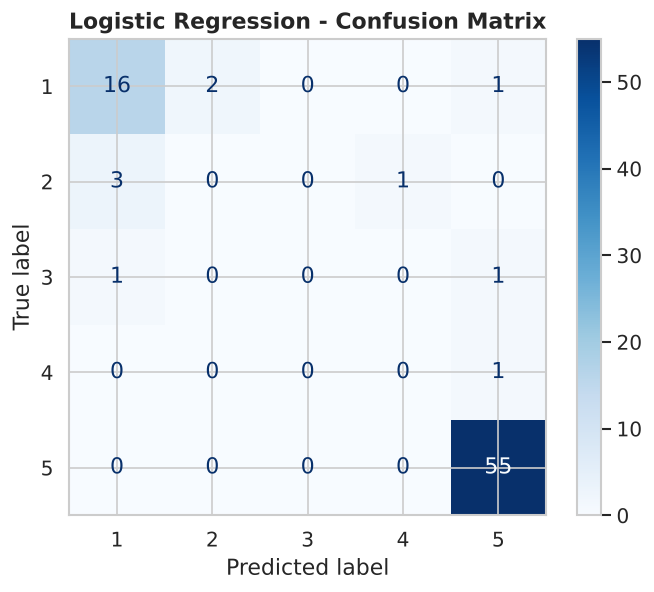

In [15]:
# logistic regression
# class_weight=balanced helps a bit with the imbalanced classes
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    solver='lbfgs',
    random_state=42
)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

lr_acc = accuracy_score(y_test, y_pred_lr)
print(f"Logistic Regression accuracy: {lr_acc:.4f} ({lr_acc*100:.2f}%)")
print()
print(classification_report(y_test, y_pred_lr, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(lr_model, X_test, y_test, cmap='Blues', ax=ax)
ax.set_title('Logistic Regression - Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()


logistic regression got **87.65% accuracy**. handles 5-star (f1 = 0.97) and 1-star (f1 = 0.82) well. completely failed on 2, 3 and 4-star (f1 = 0.00) — only 4, 2 and 1 test samples for those classes so it never had a chance. the high accuracy is basically just because 55 out of 81 test reviews are 5-star.

#### model 2 — random forest

Random Forest accuracy: 0.8889 (88.89%)

              precision    recall  f1-score   support

           1       0.77      0.89      0.83        19
           2       0.00      0.00      0.00         4
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         1
           5       0.93      1.00      0.96        55

    accuracy                           0.89        81
   macro avg       0.34      0.38      0.36        81
weighted avg       0.81      0.89      0.85        81



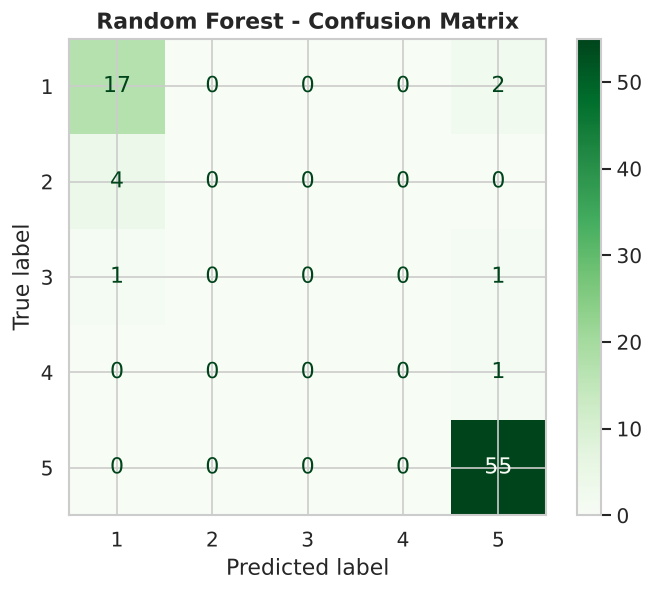

In [16]:
# random forest -- 200 trees, balanced class weights
rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)

rf_acc = accuracy_score(y_test, y_pred_rf)
print(f"Random Forest accuracy: {rf_acc:.4f} ({rf_acc*100:.2f}%)")
print()
print(classification_report(y_test, y_pred_rf, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Greens', ax=ax)
ax.set_title('Random Forest - Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()


random forest got **88.89% accuracy**, slightly higher than lr. also handles 5-star (f1 = 0.96) and 1-star (f1 = 0.83) ok but completely fails on 2, 3 and 4-star. 200 trees didn't help with the imbalance. confusion matrix looks almost the same as lr.

#### model 3 — naive bayes

Naive Bayes accuracy: 0.8519 (85.19%)

              precision    recall  f1-score   support

           1       0.78      0.74      0.76        19
           2       0.00      0.00      0.00         4
           3       0.00      0.00      0.00         2
           4       0.00      0.00      0.00         1
           5       0.87      1.00      0.93        55

    accuracy                           0.85        81
   macro avg       0.33      0.35      0.34        81
weighted avg       0.78      0.85      0.81        81



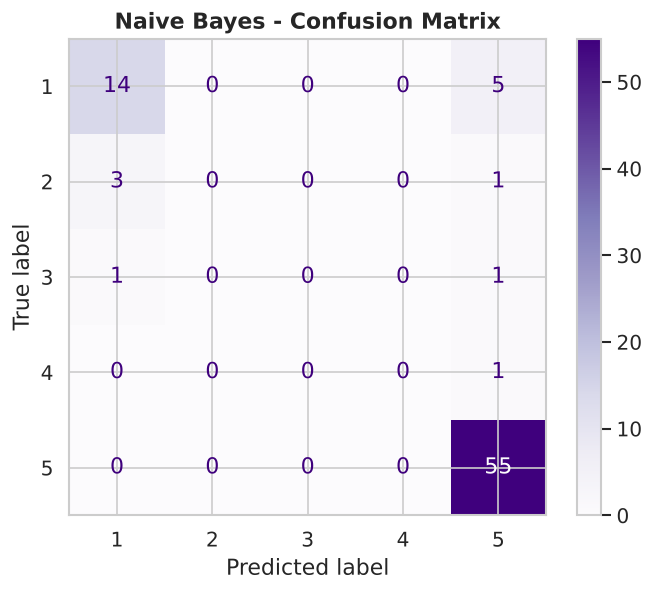

In [17]:
# naive bayes -- can only use tfidf here, not the numeric features
# (MultinomialNB doesn't accept negative values)
# same train/test split as above, separate tfidf fitted on train only
tfidf_nb = TfidfVectorizer(max_features=2000, ngram_range=(1, 2), min_df=2)
X_train_nb = tfidf_nb.fit_transform(df.loc[train_idx, 'review'])
X_test_nb  = tfidf_nb.transform(df.loc[test_idx, 'review'])
y_train_nb, y_test_nb = y_train, y_test

nb_model = MultinomialNB()
nb_model.fit(X_train_nb, y_train_nb)
y_pred_nb = nb_model.predict(X_test_nb)

nb_acc = accuracy_score(y_test_nb, y_pred_nb)
print(f"Naive Bayes accuracy: {nb_acc:.4f} ({nb_acc*100:.2f}%)")
print()
print(classification_report(y_test_nb, y_pred_nb, zero_division=0))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(nb_model, X_test_nb, y_test_nb, cmap='Purples', ax=ax)
ax.set_title('Naive Bayes - Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()


naive bayes got **85.19% accuracy**, lowest of the three. same story — fails on 2, 3 and 4-star. slightly weaker because it can only use tfidf, not the numeric features. still the simplest and fastest model though.

## 7. Results & Comparison

comparing all three models on accuracy and macro f1. macro f1 is more honest here because it doesn't get inflated by the 5-star class.

In [18]:
# compare all three models
from sklearn.metrics import f1_score

results = {
    'Model': ['Logistic Regression', 'Random Forest', 'Naive Bayes'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test_nb, y_pred_nb)
    ],
    'Macro F1': [
        f1_score(y_test, y_pred_lr, average='macro', zero_division=0),
        f1_score(y_test, y_pred_rf, average='macro', zero_division=0),
        f1_score(y_test_nb, y_pred_nb, average='macro', zero_division=0)
    ],
    'Class 1 F1': [
        f1_score(y_test, y_pred_lr, labels=[1], average='macro', zero_division=0),
        f1_score(y_test, y_pred_rf, labels=[1], average='macro', zero_division=0),
        f1_score(y_test_nb, y_pred_nb, labels=[1], average='macro', zero_division=0)
    ],
    'Class 5 F1': [
        f1_score(y_test, y_pred_lr, labels=[5], average='macro', zero_division=0),
        f1_score(y_test, y_pred_rf, labels=[5], average='macro', zero_division=0),
        f1_score(y_test_nb, y_pred_nb, labels=[5], average='macro', zero_division=0)
    ]
}

results_df = pd.DataFrame(results)
for col in ['Accuracy', 'Macro F1', 'Class 1 F1', 'Class 5 F1']:
    results_df[col] = results_df[col].apply(lambda x: f'{x:.4f}')
print(results_df.to_string(index=False))


              Model Accuracy Macro F1 Class 1 F1 Class 5 F1
Logistic Regression   0.8765   0.3588     0.8205     0.9735
      Random Forest   0.8889   0.3588     0.8293     0.9649
        Naive Bayes   0.8519   0.3378     0.7568     0.9322


all three models are between 85-89% accuracy but macro f1 is only around **0.34-0.36**. that gap tells the real story — good at predicting 1-star and 5-star, basically useless for the middle classes. random forest has the best accuracy (88.89%) and ties with logistic regression on macro f1 (0.3588), so the two are practically equal; naive bayes is a bit behind.

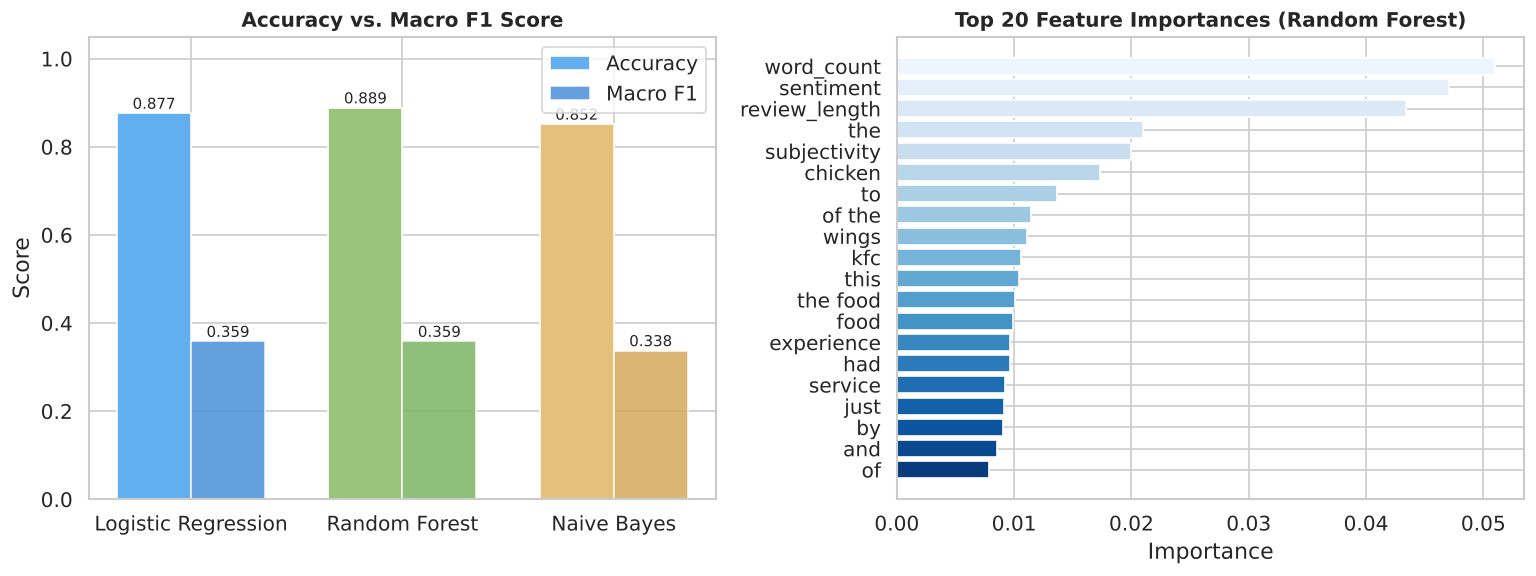

In [19]:
# bar chart: accuracy vs macro f1 for all three models
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

models   = ['LR', 'RF', 'NB']
acc_vals = [
    accuracy_score(y_test, y_pred_lr),
    accuracy_score(y_test, y_pred_rf),
    accuracy_score(y_test_nb, y_pred_nb)
]
macro_f1 = [
    f1_score(y_test, y_pred_lr, average='macro', zero_division=0),
    f1_score(y_test, y_pred_rf, average='macro', zero_division=0),
    f1_score(y_test_nb, y_pred_nb, average='macro', zero_division=0)
]

x = np.arange(len(models))
width = 0.35

axes[0].bar(x - width/2, acc_vals, width, label='Accuracy',
            color=['#61afef', '#98c379', '#e5c07b'], edgecolor='white')
axes[0].bar(x + width/2, macro_f1, width, label='Macro F1',
            color=['#4a90d9', '#7ab565', '#d4a85a'], edgecolor='white', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(['Logistic Regression', 'Random Forest', 'Naive Bayes'])
axes[0].set_title('Accuracy vs. Macro F1 Score', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1.05)
axes[0].legend()
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width() / 2,
                 bar.get_height() + 0.01, f'{bar.get_height():.3f}',
                 ha='center', fontsize=9)

# feature importance from random forest -- which features matter most?
feat_names  = tfidf.get_feature_names_out().tolist() +               ['sentiment', 'subjectivity', 'review_length', 'word_count']
importances = rf_model.feature_importances_
top_idx     = np.argsort(importances)[-20:][::-1]
top_feats   = [feat_names[i] for i in top_idx]
top_vals    = importances[top_idx]

axes[1].barh(top_feats[::-1], top_vals[::-1], color=sns.color_palette('Blues_r', 20))
axes[1].set_title('Top 20 Feature Importances (Random Forest)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Importance')

plt.tight_layout()
plt.show()


the bar chart confirms all three are very close. feature importance from random forest shows the **numeric features** matter most — word count, sentiment score and review length are the top three, followed by subjectivity. among words, "chicken", "wings" and "kfc" rank highest (plus some filler words like "the" and "to", which mostly act as a proxy for longer, more negative reviews).

## 8. Conclusion

i looked at 402 unique kfc trustpilot reviews to see whether what people write matches the star rating they give.

ratings are very polarised — about 68% are 5-star and 23% are 1-star. very few people leave anything in between. people mostly only bother reviewing when they feel strongly.

text and ratings mostly do match. pearson r = 0.64 so there's a clear link between sentiment and star rating.

but not always. found 11 mismatches (2.7%). most were positive-sounding text with a low rating. could be sarcasm, polite writing, or textblob not being sensitive enough.

ml models got 85-89% accuracy but macro f1 was only around 0.35. the models learn to predict 1 and 5 stars well but ignore the rest because of the class imbalance. random forest and logistic regression were practically tied.

data quality notes: the raw scrape had 78 duplicate rows (featured reviews repeated on every page) and 40 truncated reviews — both are handled in the notebook, but the scraper should be improved to open each review and skip featured ones.

things that could be improved:
- collect more 2, 3, and 4-star reviews to fix the imbalance
- try smote or other oversampling
- use a better model like roberta instead of textblob
- look at aspect-based sentiment to find out what specifically people like or dislike